# Camera calibration with a checkerboard

Every metric thing a robot does with a camera (measuring distances, estimating object poses, visual odometry, fusing
with lidar) needs the camera's **intrinsics** $K$ and its **lens distortion**. This notebook calibrates a real camera
from 13 checkerboard photos with Zhang's method, diagnoses the result, undistorts images, and measures how the
estimate depends on the number of views.

**What it does**

1. Detects the 9x6 inner corners in OpenCV's `left*.jpg` calibration set with the classic detector + sub-pixel refinement
   and compares it with the sector-based `findChessboardCornersSB`.
2. Runs `cv2.calibrateCameraExtended`: $K$, distortion, per-view poses, parameter uncertainties and per-view errors.
3. Diagnoses the calibration with reprojection residuals and leave-one-out hold-out errors, traces two inconsistent views back
   to the corner-refinement window, and picks that window by hold-out error; then visualises all board poses in 3D.
4. Undistorts images (two choices of the new camera matrix) and measures how straight the board's grid lines become.
5. Repeats the calibration on random subsets of 3-12 views and measures parameter spread and **hold-out** reprojection error.

**What you'll learn**

- the full camera model (intrinsics + Brown-Conrady distortion + extrinsics) and Zhang's planar calibration method
- what the RMS reprojection error does and does not tell you, and why hold-out error is the honest metric
- how to spot a bad calibration view, find its cause, and how many views you need
- undistortion with precomputed remap tables, as used on a robot at frame rate

**Prerequisites**: notebook `01_image_formation_filtering_edges` (pinhole projection, distortion model) and
`02_features_homography_panorama` (homographies). Data: `make data-01_classical_cv`. Runs on the CPU in under a minute.

## 0. Setup

The images are OpenCV's sample calibration set (640x480 greyscale, a hand-held 10x7-square board, i.e. **9x6 inner
corners**; note there is no `left10.jpg`). The physical square size is not documented, so we use **1 unit = 1 square**:
intrinsics and distortion are in pixels/unitless and are unaffected, but translations come out in "squares".
Multiply by the real square size (e.g. 0.025 m) to get metres.

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
13 images from data/01_classical_cv/calib: left01, left02, left03, left04, left05, left06, left07, left08, left09, left11, left12, left13, left14 | size 640x480


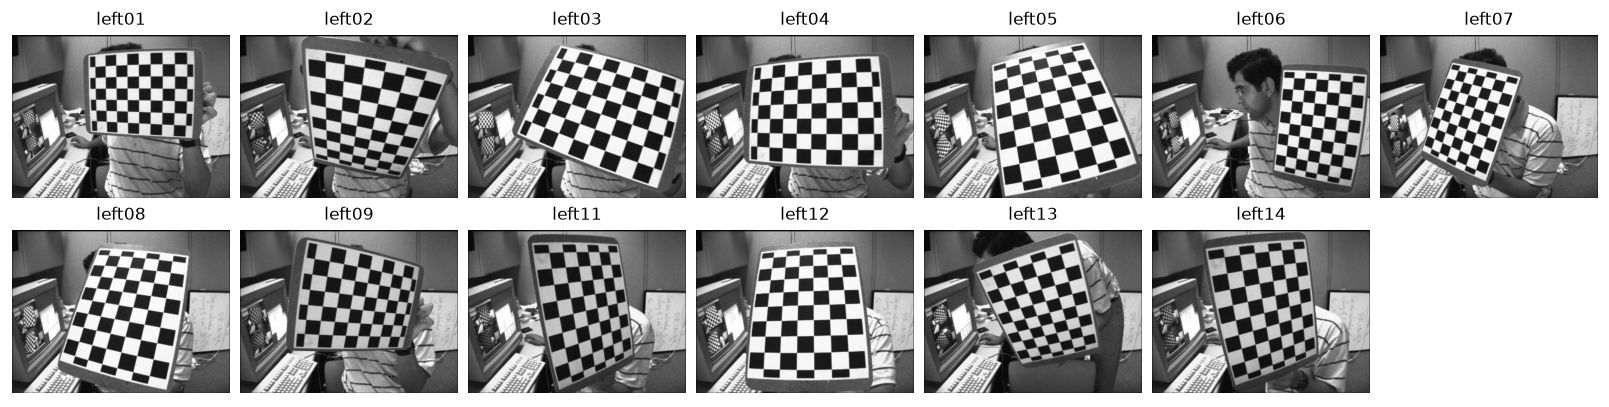

In [1]:
# --- Setup: imports, seeding, paths and the 13 calibration images ---
import itertools
import time
from io import BytesIO

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as IPImage
from IPython.display import display
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

from cvlab import device as cvdevice
from cvlab import geometry, io, viz
from cvlab.bench import Timer, benchmark

device = cvdevice.setup(seed=0)
viz.set_style()
rng = np.random.default_rng(0)
PROJECT = "01_classical_cv"
ROOT = io.repo_root()
CALIB = io.data_dir("01_classical_cv", "calib")
RESULTS_DIR = io.project_dir(PROJECT) / "results"
RESULTS_DIR.mkdir(exist_ok=True)
results = {}
T_START = time.perf_counter()  # wall-clock start; the notebook runtime is reported in the summary cell


def show_jpeg(fig, quality=80):
    # Photo-like figures are embedded as JPEG to keep the committed notebook small.
    buf = BytesIO()
    fig.savefig(buf, format="jpeg", pil_kwargs={"quality": quality})
    plt.close(fig)
    display(IPImage(buf.getvalue()))


PATTERN = (9, 6)  # inner corners per row, per column
SQUARE = 1.0      # board square size in "units" (unknown for this data set)
files = sorted(CALIB.glob("left*.jpg"))
names = [f.stem for f in files]
images = [cv2.imread(str(f), cv2.IMREAD_GRAYSCALE) for f in files]  # (480, 640) uint8 each
h, w = images[0].shape
print(f"{len(files)} images from {CALIB.relative_to(ROOT)}: {', '.join(names)} | size {w}x{h}")
fig = viz.show_images(images, names, ncols=7, size=1.9, cmap="gray")
show_jpeg(fig)

## 1. The model and Zhang's method

For view $i$ the board pose is $(R_i, \mathbf{t}_i)$ (board -> camera) and corner $j$ has board coordinates
$\mathbf{X}_j = (x_j, y_j, 0)$. The predicted pixel is

$$ \hat{\mathbf{u}}_{ij} = \pi\big(K, \mathbf{d}, R_i\mathbf{X}_j + \mathbf{t}_i\big), \qquad \mathbf{d} = (k_1, k_2, p_1, p_2, k_3), $$

with the projection and distortion model from notebook 01. Calibration minimises the **reprojection error**

$$ \min_{K,\mathbf{d},\{R_i,\mathbf{t}_i\}} \sum_{i,j} \lVert \mathbf{u}_{ij} - \hat{\mathbf{u}}_{ij}\rVert^2,
\qquad \mathrm{RMS} = \sqrt{\tfrac{1}{N}\textstyle\sum_{i,j}\lVert \mathbf{u}_{ij} - \hat{\mathbf{u}}_{ij}\rVert^2}. $$

This is non-convex, so **Zhang's method** (2000) first gets a closed-form initialisation: because the board is planar
($z = 0$), each view is a homography $H_i = \lambda K[\mathbf{r}_1\ \mathbf{r}_2\ \mathbf{t}]$. Since $\mathbf{r}_1, \mathbf{r}_2$ are
orthonormal, $\mathbf{h}_1^\top B\,\mathbf{h}_2 = 0$ and $\mathbf{h}_1^\top B\,\mathbf{h}_1 = \mathbf{h}_2^\top B\,\mathbf{h}_2$ with
$B = K^{-\top}K^{-1}$: two linear constraints per view, so $\ge 3$ views (in general position) determine $K$. Poses follow
from $K^{-1}H_i$, distortion starts at zero, and Levenberg-Marquardt refines everything jointly.

The board points are a regular grid, x varying fastest, which must match the detector's corner order:

In [2]:
# --- 3D board coordinates of the 54 inner corners (z = 0 plane, units of squares) ---
obj = np.zeros((PATTERN[0] * PATTERN[1], 3), np.float32)
obj[:, :2] = np.mgrid[0:PATTERN[0], 0:PATTERN[1]].T.reshape(-1, 2) * SQUARE  # (54, 3)
print(obj[:3], "...", obj[-1], obj.shape)

[[0. 0. 0.]
 [1. 0. 0.]
 [2. 0. 0.]] ... [8. 5. 0.] (54, 3)


## 2. Corner detection

- **`findChessboardCorners`** binarises the image (adaptive threshold), finds the black quads and links them into a grid;
  its corners are only pixel accurate.
- **`cornerSubPix`** refines each corner $\mathbf{q}$ using the fact that for every pixel $\mathbf{p}_k$ near a true corner the
  image gradient is orthogonal to $\mathbf{p}_k - \mathbf{q}$: it solves $\sum_k \nabla I(\mathbf{p}_k)\nabla I(\mathbf{p}_k)^\top(\mathbf{q} - \mathbf{p}_k) = 0$
  iteratively over a search window. `winSize=(11, 11)` is a **half**-size, i.e. a 23x23 px window; this is the value used in
  OpenCV's calibration tutorial, so we start with it.
- **`findChessboardCornersSB`** (Duda & Frese 2018) uses a sector-based filter response and is usually more accurate and more
  robust to noise, but stricter about the full board being visible and well imaged.

**OpenCV 5:** detected corners are returned as `(N, 2)` float32 arrays (OpenCV 4 returned `(N, 1, 2)`). Also, the SB detector
may enumerate the grid starting from the opposite corner, so we align the ordering before comparing.

In [3]:
# --- Detect corners in all views: classic (pixel level) + cornerSubPix(11x11) and the SB detector ---
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 1e-3)
TUTORIAL_WIN = (11, 11)  # half-size -> 23x23 px search window

def refine(img, c_pixel, win):
    return cv2.cornerSubPix(img, c_pixel.copy(), win, (-1, -1), criteria)  # (54, 2) float32

corners_px, corners_sb, det_rows = [], {}, []
for name, img in zip(names, images):
    with Timer() as t_classic:
        ok, c = cv2.findChessboardCorners(img, PATTERN, flags=cv2.CALIB_CB_ADAPTIVE_THRESH | cv2.CALIB_CB_NORMALIZE_IMAGE)
    assert ok, f"classic detector failed on {name}"
    corners_px.append(c)
    with Timer() as t_sb:
        ok_sb, c_sb = cv2.findChessboardCornersSB(img, PATTERN, flags=cv2.CALIB_CB_EXHAUSTIVE | cv2.CALIB_CB_ACCURACY)
    if ok_sb:
        if np.linalg.norm(c_sb[::-1] - c, axis=1).mean() < np.linalg.norm(c_sb - c, axis=1).mean():
            c_sb = c_sb[::-1].copy()  # same grid, enumerated from the opposite corner
        corners_sb[name] = c_sb
    square_px = np.median(np.linalg.norm(np.diff(c.reshape(PATTERN[1], PATTERN[0], 2), axis=1), axis=2))
    det_rows.append({"view": name, "classic_ms": t_classic.ms, "square_size_px": float(square_px),
                     "sb_found": bool(ok_sb), "sb_ms": t_sb.ms})
corners_tut = [refine(img, c, TUTORIAL_WIN) for img, c in zip(images, corners_px)]
for row, c0, c1 in zip(det_rows, corners_px, corners_tut):
    row["subpix_shift_mean_px"] = float(np.linalg.norm(c1 - c0, axis=1).mean())
df_detect = pd.DataFrame(det_rows)
results["detection"] = det_rows
print(f"corners shape {corners_px[0].shape} {corners_px[0].dtype} | classic: {len(corners_px)}/{len(images)} views, "
      f"SB: {len(corners_sb)}/{len(images)} views (missing: {sorted(set(names) - set(corners_sb))})")
df_detect.round(3)

corners shape (54, 2) float32 | classic: 13/13 views, SB: 12/13 views (missing: ['left05'])


,view,classic_ms,square_size_px,sb_found,sb_ms,subpix_shift_mean_px
0,left01,3.145,33.455,True,77.906,0.191
1,left02,3.628,33.957,True,55.848,0.685
2,left03,1.929,45.481,True,54.448,0.281
3,left04,1.593,42.825,True,51.431,0.170
4,left05,1.804,42.367,False,123.847,0.306
5,left06,12.142,34.416,True,52.790,0.393
6,left07,1.654,32.195,True,44.929,0.255
7,left08,1.551,41.663,True,56.302,0.279
8,left09,2.966,35.605,True,65.685,0.308
9,left11,4.050,40.924,True,50.238,0.239


`drawChessboardCorners` colours the rows so you can check the ordering (first corner = red end).

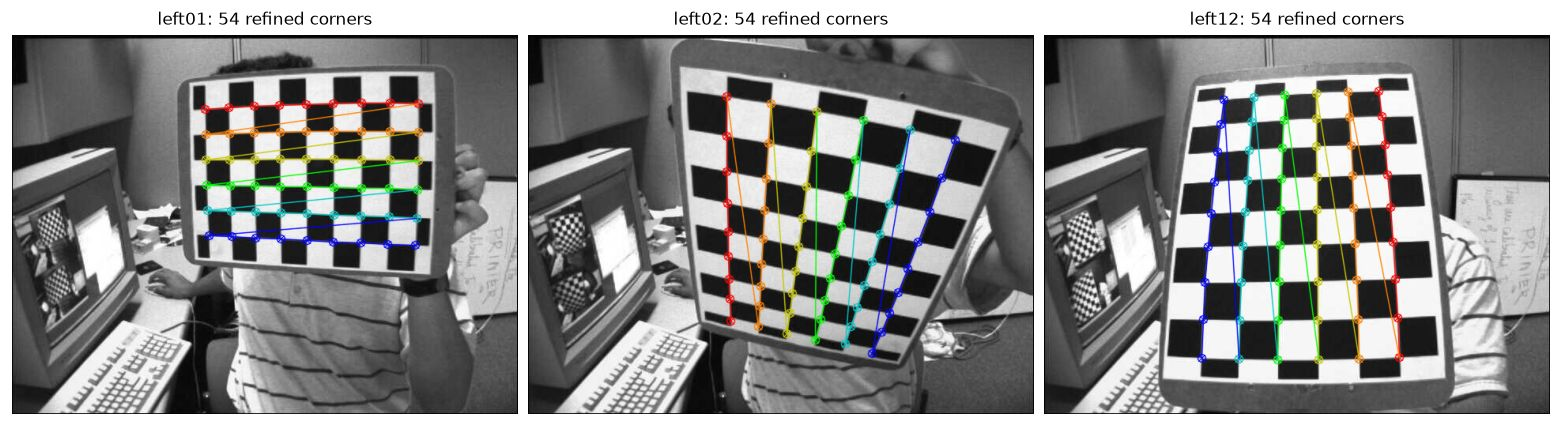

In [4]:
# --- Visualise detected corners on three views ---
show = ["left01", "left02", "left12"]
vis = []
for name in show:
    i = names.index(name)
    v = cv2.cvtColor(images[i], cv2.COLOR_GRAY2BGR)
    cv2.drawChessboardCorners(v, PATTERN, corners_tut[i], True)
    vis.append(cv2.cvtColor(v, cv2.COLOR_BGR2RGB))
fig = viz.show_images(vis, [f"{n}: 54 refined corners" for n in show], ncols=3, size=4.3)
show_jpeg(fig)

## 3. Calibration

`calibrateCameraExtended` returns the overall RMS, $K$, the distortion vector, one `rvec`/`tvec` per view, **standard
deviations** of the intrinsics (from the inverse of the approximate Hessian $J^\top J$ at the optimum, scaled by the residual
variance) and the per-view RMS errors. The standard deviations assume the model is right and the noise is i.i.d. Gaussian,
so they describe random noise only, not systematic errors.

In [5]:
# --- Calibrate with all 13 views (tutorial corners) and report parameters with 1-sigma uncertainties ---
param_names = ["fx", "fy", "cx", "cy", "k1", "k2", "p1", "p2", "k3"]

def calibrate(corner_list):
    rms_, K_, d_, rv_, tv_, s_int, _, pv_ = cv2.calibrateCameraExtended(
        [obj] * len(corner_list), corner_list, (w, h), None, None)
    d_ = d_.ravel()
    vals = [K_[0, 0], K_[1, 1], K_[0, 2], K_[1, 2], *d_[:5]]
    return dict(rms=rms_, K=K_, dist=d_, rvecs=rv_, tvecs=tv_, std=s_int.ravel()[:9], per_view=pv_.ravel(), values=vals)

with Timer() as t_cal:
    cal_tut = calibrate(corners_tut)
results["calibration_tutorial_window"] = {k: cal_tut[k] for k in ["rms", "K", "dist", "std", "per_view"]}
print(f"RMS reprojection error {cal_tut['rms']:.4f} px over {13 * len(obj)} corners ({t_cal.ms:.0f} ms)")
pd.DataFrame({"parameter": param_names, "value": cal_tut["values"], "std (1 sigma)": cal_tut["std"]}).round(5)

RMS reprojection error 0.4087 px over 702 corners (13 ms)


,parameter,value,std (1 sigma)
0,fx,536.07345,0.92800
1,fy,536.01636,0.97196
2,cx,342.37047,0.97154
3,cy,235.53687,1.07061
4,k1,-0.26509,0.01164
5,k2,-0.04674,0.09084
6,p1,0.00183,0.00024
7,p2,-0.00031,0.00030
8,k3,0.25231,0.19752


### 3.1 Residuals: is the calibration good, and which view is bad?

We recompute the residuals ourselves with `cv2.projectPoints` (its output is `(N, 1, 2)`) and check that our per-view RMS and
overall RMS reproduce OpenCV's numbers. A good calibration leaves small, isotropic, structure-free residuals; a systematic
pattern points to an under-modelled lens or to bad measurements.

overall RMS ours 0.4087 vs OpenCV 0.4087 px | max per-view difference 1.9e-06 px


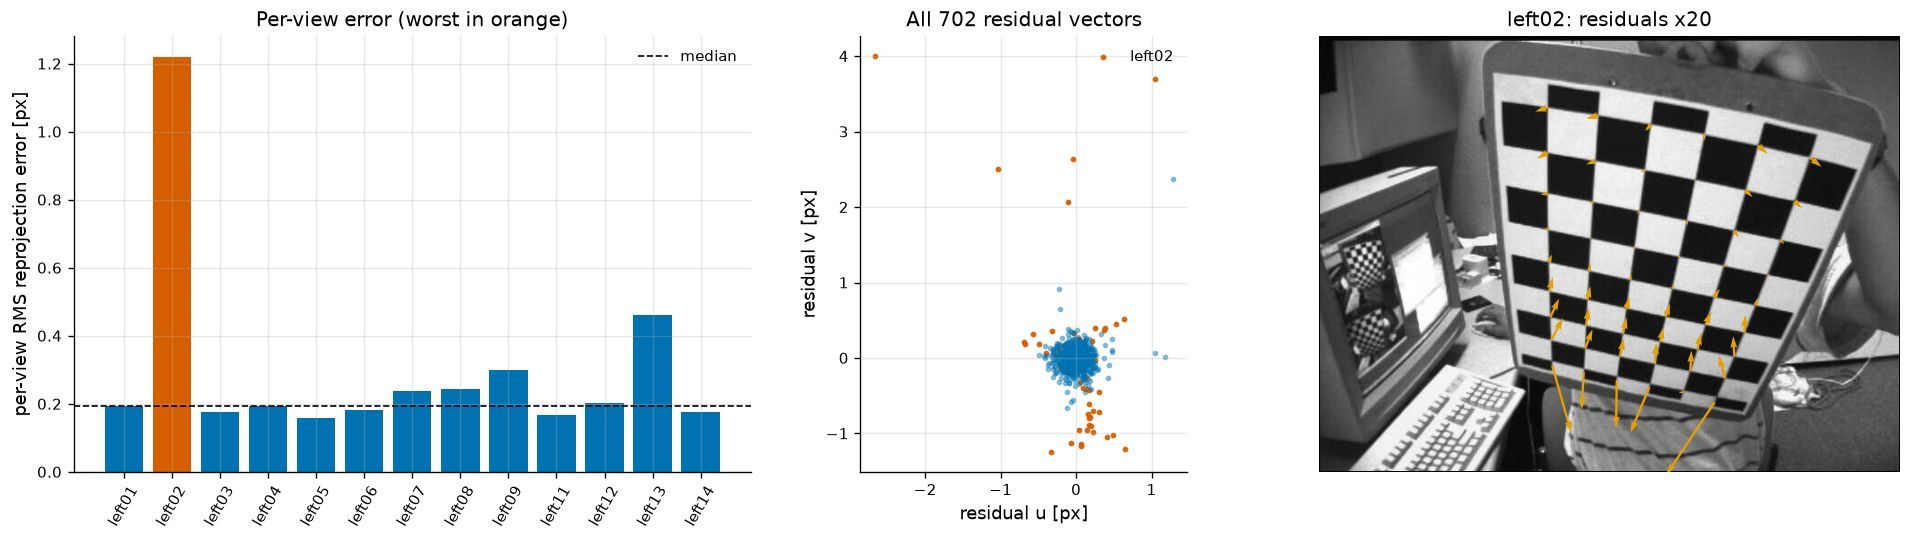

In [6]:
# --- Recompute residuals, plot per-view RMS, residual scatter and the worst view's residual field ---
def view_residuals(cal, corner_list):
    res = []
    for c, rv, tv in zip(corner_list, cal["rvecs"], cal["tvecs"]):
        proj, _ = cv2.projectPoints(obj, rv, tv, cal["K"], cal["dist"])  # (54, 1, 2)
        res.append(c - proj.reshape(-1, 2))                              # measured - predicted [px]
    return res

residuals = view_residuals(cal_tut, corners_tut)
per_view_tut = np.array([np.sqrt((r**2).sum(1).mean()) for r in residuals])
rms_ours = np.sqrt(np.mean(np.concatenate([(r**2).sum(1) for r in residuals])))
print(f"overall RMS ours {rms_ours:.4f} vs OpenCV {cal_tut['rms']:.4f} px | max per-view difference "
      f"{np.abs(per_view_tut - cal_tut['per_view']).max():.1e} px")
worst = int(per_view_tut.argmax())

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw={"width_ratios": [1.3, 1, 1.2]})
cols = [viz.color(5, True) if i == worst else viz.color(0, True) for i in range(len(names))]
axes[0].bar(names, per_view_tut, color=cols)
axes[0].axhline(np.median(per_view_tut), color="k", ls="--", lw=1, label="median")
axes[0].set_ylabel("per-view RMS reprojection error [px]")
axes[0].set_title("Per-view error (worst in orange)")
axes[0].tick_params(axis="x", rotation=60)
axes[0].legend()
for i, r in enumerate(residuals):
    axes[1].scatter(r[:, 0], r[:, 1], s=6, color=viz.color(5 if i == worst else 0, True),
                    alpha=0.9 if i == worst else 0.4, label=names[i] if i == worst else None)
axes[1].set_aspect("equal")
axes[1].set_xlabel("residual u [px]")
axes[1].set_ylabel("residual v [px]")
axes[1].set_title("All 702 residual vectors")
axes[1].legend()
axes[2].imshow(images[worst], cmap="gray")
cw = corners_tut[worst]
axes[2].quiver(cw[:, 0], cw[:, 1], residuals[worst][:, 0], residuals[worst][:, 1], color=viz.color(1, True),
               angles="xy", scale_units="xy", scale=1 / 20, width=0.004)
axes[2].set_title(f"{names[worst]}: residuals x20")
axes[2].axis("off")
show_jpeg(fig)

### 3.2 Leave-one-out: can the other views predict this one?

Training error is optimistic: every view pulls the parameters towards itself. The honest test is **hold-out error**: calibrate
on 12 views, then for the left-out view estimate *only its pose* with `solvePnP` (intrinsics fixed) and measure its reprojection
RMS. A view that is consistent with the rest gets a hold-out error close to its training error; a view whose measurements
disagree with the others stands out.

In [7]:
# --- Leave-one-out hold-out error per view ---
def holdout_rms(Kn, dn, ids, corner_list):
    sq = []
    for i in ids:
        _, rv, tv = cv2.solvePnP(obj, corner_list[i], Kn, dn)
        proj, _ = cv2.projectPoints(obj, rv, tv, Kn, dn)
        sq.append(((corner_list[i] - proj.reshape(-1, 2)) ** 2).sum(1))
    return float(np.sqrt(np.mean(np.concatenate(sq))))

def leave_one_out(corner_list):
    out = []
    for i in range(len(corner_list)):
        rest = [c for j, c in enumerate(corner_list) if j != i]
        _, Kn, dn, _, _ = cv2.calibrateCamera([obj] * len(rest), rest, (w, h), None, None)
        out.append(holdout_rms(Kn, dn.ravel(), [i], corner_list))
    return np.array(out)

loo_tut = leave_one_out(corners_tut)
df_loo = pd.DataFrame({"view": names, "training_rms_px": per_view_tut, "leave_one_out_rms_px": loo_tut})
results["leave_one_out_tutorial_window"] = df_loo.to_dict("records")
df_loo.set_index("view").T.round(3)

view,left01,left02,left03,left04,left05,left06,left07,left08,left09,left11,left12,left13,left14
training_rms_px,0.193,1.220,0.175,0.194,0.159,0.183,0.238,0.243,0.301,0.168,0.202,0.462,0.175
leave_one_out_rms_px,0.200,1.243,0.191,0.199,0.164,0.204,0.241,0.255,0.305,0.181,0.213,0.465,0.181


Two views cannot be predicted by the others, and the residual field of the worst one shows *where*: the errors concentrate on
the row of corners next to the board's outer edge, all pointing the same way. Distortion cannot cause that (it is smooth
across the image), so the corner measurements themselves are suspicious. Zooming in on the pixel-level corners refined with
different `cornerSubPix` windows reveals the cause:

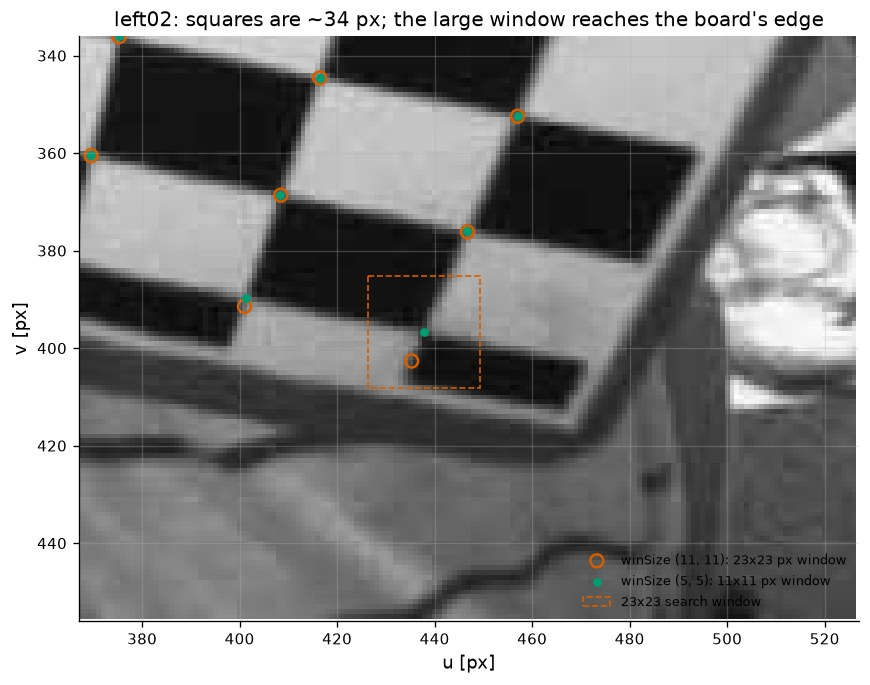

In [8]:
# --- Zoom: corners of the worst view near the board edge, refined with a 23x23 vs a 11x11 px window ---
i = worst
c11, c5 = corners_tut[i], refine(images[i], corners_px[i], (5, 5))
r_edge = np.argmax(np.linalg.norm(c11 - c5, axis=1))  # corner moved most by the large window
x0, y0 = np.clip(c5[r_edge].astype(int) - [70, 60], 0, None)
crop = cv2.cvtColor(images[i][y0:y0 + 120, x0:x0 + 160], cv2.COLOR_GRAY2RGB)
fig, ax = plt.subplots(figsize=(7.5, 5.6))
ax.imshow(crop, extent=(x0 - 0.5, x0 + crop.shape[1] - 0.5, y0 + crop.shape[0] - 0.5, y0 - 0.5))
ax.scatter(*c11.T, s=60, facecolors="none", edgecolors=[viz.color(5, True)], lw=1.5, label="winSize (11, 11): 23x23 px window")
ax.scatter(*c5.T, s=18, color=viz.color(2, True), label="winSize (5, 5): 11x11 px window")
sq = det_rows[i]["square_size_px"]
ax.add_patch(plt.Rectangle(c5[r_edge] - 11.5, 23, 23, fill=False, ls="--", color=viz.color(5, True), label="23x23 search window"))
ax.set_xlim(x0, x0 + crop.shape[1])
ax.set_ylim(y0 + crop.shape[0], y0)
ax.set_xlabel("u [px]")
ax.set_ylabel("v [px]")
ax.legend(loc="lower right", fontsize=8)
ax.set_title(f"{names[i]}: squares are ~{sq:.0f} px; the large window reaches the board's edge")
show_jpeg(fig, quality=88)

### 3.3 Choosing the refinement window by hold-out error

The large window includes the strong gradients of the board's outer border, which do not belong to the corner and drag it
away. Too small a window, on the other hand, uses few pixels and is noisier. Instead of guessing, we sweep the half-size, and
for each value report the training RMS, the mean leave-one-out error, $f_x$, and the mean distance to the corners of the
independent SB detector (on the 12 views where it succeeds). We keep the window with the lowest mean hold-out error.

In [9]:
# --- Sweep the cornerSubPix half-window: training RMS, leave-one-out error, fx, agreement with SB corners ---
win_rows, refined = [], {}
for half in [3, 5, 7, 9, 11]:
    cl = [refine(img, c, (half, half)) for img, c in zip(images, corners_px)]
    cal = calibrate(cl)
    loo = leave_one_out(cl)
    sb_dist = np.mean([np.linalg.norm(corners_sb[n] - c, axis=1).mean() for n, c in zip(names, cl) if n in corners_sb])
    refined[half] = (cl, cal, loo)
    win_rows.append({"half_window": half, "window_px": 2 * half + 1, "train_rms_px": cal["rms"],
                     "loo_mean_px": loo.mean(), "loo_max_px": loo.max(), "fx": cal["K"][0, 0], "std_fx": cal["std"][0],
                     "mean_dist_to_SB_px": sb_dist})
df_win = pd.DataFrame(win_rows)
best_half = int(df_win.loc[df_win["loo_mean_px"].idxmin(), "half_window"])
corners, cal, loo_best = refined[best_half]
K, dist = cal["K"], cal["dist"]
sb_cal = calibrate([corners_sb[n] for n in names if n in corners_sb])
results["window_sweep"] = win_rows
results["best_half_window"] = best_half
results["calibration_final"] = {k: cal[k] for k in ["rms", "K", "dist", "std", "per_view"]}
results["calibration_sb_12_views"] = {"rms": sb_cal["rms"], "K": sb_cal["K"], "dist": sb_cal["dist"]}
print(f"best half-window: {best_half} ({2 * best_half + 1}x{2 * best_half + 1} px) | "
      f"SB-only calibration (12 views): fx = {sb_cal['K'][0, 0]:.2f} px, RMS {sb_cal['rms']:.3f} px")
df_win.round(3)

best half-window: 7 (15x15 px) | SB-only calibration (12 views): fx = 532.35 px, RMS 0.235 px


,half_window,window_px,train_rms_px,loo_mean_px,loo_max_px,fx,std_fx,mean_dist_to_SB_px
0,3,7,0.230,0.234,0.301,532.439,0.516,0.227
1,5,11,0.195,0.200,0.267,532.827,0.438,0.188
2,7,15,0.183,0.187,0.252,533.002,0.411,0.172
3,9,19,0.198,0.197,0.356,533.171,0.444,0.169
4,11,23,0.409,0.311,1.243,536.073,0.928,0.214


The final calibration uses the selected window. Compare it with the tutorial-window calibration: the focal length moved by
several of the old estimate's standard deviations. The formal $\sigma$ only covers random noise, not a systematic measurement
bias, which is why independent checks (hold-out error, a second corner detector) matter.

In [10]:
# --- Final calibration (selected window) vs the tutorial window ---
cam = geometry.PinholeCamera.from_K(K, w, h)
per_view_ours = cal["per_view"]
rms = cal["rms"]
df_params = pd.DataFrame({"parameter": param_names, f"final ({2 * best_half + 1}px window)": cal["values"],
                          "std (1 sigma)": cal["std"], "tutorial (23px window)": cal_tut["values"],
                          "shift / sigma_tutorial": (np.array(cal["values"]) - np.array(cal_tut["values"])) / cal_tut["std"]})
results["fov_deg"] = cam.fov_deg
print(f"final RMS {rms:.4f} px (tutorial window: {cal_tut['rms']:.4f} px) | FOV x/y = {cam.fov_deg[0]:.1f} / {cam.fov_deg[1]:.1f} deg")
df_params.round(5)

final RMS 0.1832 px (tutorial window: 0.4087 px) | FOV x/y = 62.0 / 48.5 deg


,parameter,final (15px window),std (1 sigma),tutorial (23px window),shift / sigma_tutorial
0,fx,533.00216,0.41053,536.07345,-3.30957
1,fy,533.12448,0.43016,536.01636,-2.97530
2,cx,342.30942,0.43359,342.37047,-0.06284
3,cy,233.92922,0.47823,235.53687,-1.50163
4,k1,-0.28540,0.00508,-0.26509,-1.74510
5,k2,0.06385,0.03893,-0.04674,1.21751
6,p1,0.00111,0.00010,0.00183,-3.08414
7,p2,-0.00013,0.00013,-0.00031,0.63279
8,k3,0.08172,0.08305,0.25231,-0.86366


### 3.4 Where were the boards? Extrinsics in 3D

`rvecs`/`tvecs` give the board -> camera transform $T_{cb}$ of each view. Plotting the boards in the **camera frame** shows
how well the views cover the field of view and the range of tilts, which is what constrains the intrinsics; the inverse
$T_{bc} = T_{cb}^{-1}$ shows the same data as camera poses around a fixed board.

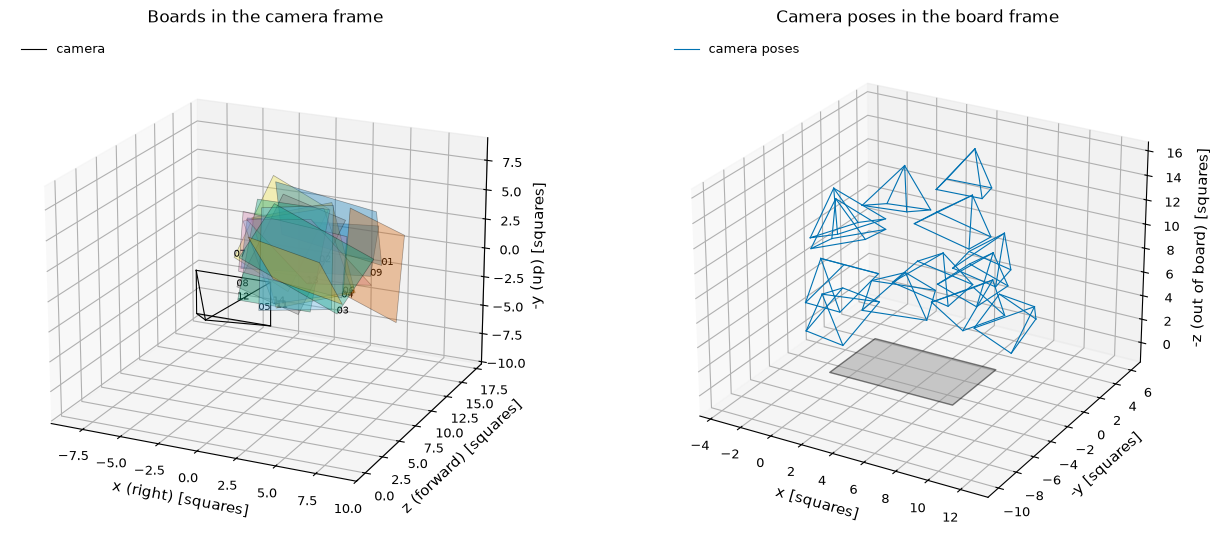

board distance 11.8-16.7 squares, tilt 15-41 deg


In [11]:
# --- Boards in the camera frame and cameras in the board frame (units: squares) ---
# Matplotlib's 3D view is z-up, so both scenes are rotated into a display frame first:
# camera frame (x right, y down, z forward) -> display (x, z, -y); board frame -> display (x, -y, -z).
M_cam = np.array([[1.0, 0, 0], [0, 0, 1], [0, -1, 0]])
M_board = np.array([[1.0, 0, 0], [0, -1, 0], [0, 0, -1]])
T_cb = [geometry.make_T(cv2.Rodrigues(rv)[0], tv.ravel()) for rv, tv in zip(cal["rvecs"], cal["tvecs"])]
outline = np.array([[0, 0, 0], [8, 0, 0], [8, 5, 0], [0, 5, 0]], float) * SQUARE  # inner-corner rectangle
fig = plt.figure(figsize=(13, 5.4))
ax = fig.add_subplot(1, 2, 1, projection="3d")
pts = [np.zeros((1, 3))]
for i, T in enumerate(T_cb):
    quad = geometry.transform_points(T, outline) @ M_cam.T
    pts.append(quad)
    ax.add_collection3d(Poly3DCollection([quad], alpha=0.35, facecolor=viz.color(i, True), edgecolor="k", lw=0.5))
    ax.text(*quad[2], names[i][-2:], fontsize=7)
viz.plot_camera_frustums(ax, geometry.make_T(M_cam, np.zeros(3))[None], K, w, h, scale=4.0,
                         color_rgb=(0, 0, 0), label="camera")
ax.scatter(*np.vstack(pts).T, s=0)  # sets the axis limits
viz.set_axes_equal(ax)
ax.view_init(elev=20, azim=-65)
ax.set_xlabel("x (right) [squares]")
ax.set_ylabel("z (forward) [squares]")
ax.set_zlabel("-y (up) [squares]")
ax.set_title("Boards in the camera frame")
ax.legend(loc="upper left")
ax = fig.add_subplot(1, 2, 2, projection="3d")
ax.add_collection3d(Poly3DCollection([outline @ M_board.T], alpha=0.5, facecolor="0.6", edgecolor="k"))
T_bc = geometry.invert_T(np.stack(T_cb))
T_disp = np.einsum("ij,njk->nik", geometry.make_T(M_board, np.zeros(3)), T_bc)  # camera poses in display frame
viz.plot_camera_frustums(ax, T_disp, K, w, h, scale=3.0, color_rgb=viz.color(0, True), label="camera poses")
ax.scatter(*np.vstack([T_disp[:, :3, 3], outline @ M_board.T]).T, s=0)
viz.set_axes_equal(ax)
ax.view_init(elev=25, azim=-60)
ax.set_xlabel("x [squares]")
ax.set_ylabel("-y [squares]")
ax.set_zlabel("-z (out of board) [squares]")
ax.set_title("Camera poses in the board frame")
ax.legend(loc="upper left")
plt.show()
dists = [np.linalg.norm(T[:3, 3]) for T in T_cb]
tilts = [np.rad2deg(np.arccos(abs(T[2, 2]))) for T in T_cb]  # angle between board normal and optical axis
results["extrinsics"] = {"distance_squares": dict(zip(names, dists)), "tilt_deg": dict(zip(names, tilts))}
print(f"board distance {min(dists):.1f}-{max(dists):.1f} squares, tilt {min(tilts):.0f}-{max(tilts):.0f} deg")

## 4. Undistortion

To undistort we need, for every pixel of the *output* image, where to sample the distorted input: apply the forward
distortion model to the output pixel's normalised ray. `initUndistortRectifyMap` precomputes these look-up tables once and
`remap` applies them every frame (that is what a robot camera driver or `image_proc` does). `getOptimalNewCameraMatrix(alpha)`
chooses the output intrinsics: `alpha=0` zooms in so every output pixel is valid (some input is cropped), `alpha=1` keeps every
input pixel (black curved borders appear).

A projective camera maps straight 3D lines to straight image lines, so undistortion should straighten the board's grid lines.
We measure straightness as the RMS orthogonal distance of each row/column of corners to its total-least-squares line, before
and after `cv2.undistortPoints(..., P=K)` (in-sample: these corners were used for calibration). The views are the final
corners with the selected refinement window.

view left06 | cv2.undistort 1.040 ms vs remap with precomputed maps 0.200 ms per 640x480 frame
alpha=0: f = 474.8 px (zoomed in) | alpha=1: f = 456.3 px (zoomed out) | original f = 533.0 px


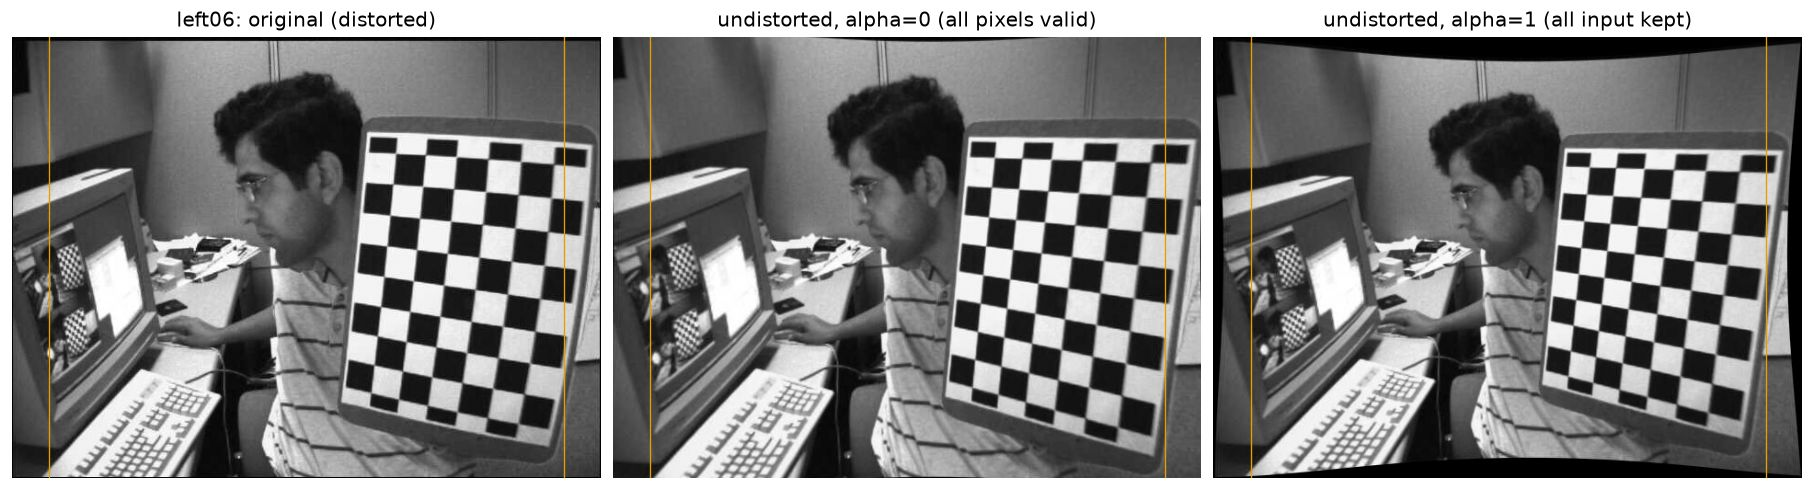

In [12]:
# --- Undistort the view whose corners reach furthest from the principal point; alpha 0 vs 1 ---
radius = [np.linalg.norm(c - [K[0, 2], K[1, 2]], axis=1).max() for c in corners]
vi = int(np.argmax(radius))
newK0, roi0 = cv2.getOptimalNewCameraMatrix(K, dist, (w, h), 0)
newK1, roi1 = cv2.getOptimalNewCameraMatrix(K, dist, (w, h), 1)
map1, map2 = cv2.initUndistortRectifyMap(K, dist, None, newK0, (w, h), cv2.CV_16SC2)  # fixed-point maps
und0 = cv2.remap(images[vi], map1, map2, cv2.INTER_LINEAR)
und1 = cv2.undistort(images[vi], K, dist, None, newK1)
t_und = benchmark(cv2.undistort, images[vi], K, dist, None, newK0, warmup=3, iters=30, cuda=False)
t_remap = benchmark(cv2.remap, images[vi], map1, map2, cv2.INTER_LINEAR, warmup=3, iters=100, cuda=False)
results["undistortion"] = {"view": names[vi], "newK_alpha0": newK0, "newK_alpha1": newK1,
                           "undistort_ms": t_und["mean_ms"], "remap_ms": t_remap["mean_ms"]}
print(f"view {names[vi]} | cv2.undistort {t_und['mean_ms']:.3f} ms vs remap with precomputed maps "
      f"{t_remap['mean_ms']:.3f} ms per 640x480 frame")
print(f"alpha=0: f = {newK0[0, 0]:.1f} px (zoomed in) | alpha=1: f = {newK1[0, 0]:.1f} px (zoomed out) | original f = {K[0, 0]:.1f} px")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.0))
for ax, im, title in [(axes[0], images[vi], f"{names[vi]}: original (distorted)"),
                      (axes[1], und0, "undistorted, alpha=0 (all pixels valid)"),
                      (axes[2], und1, "undistorted, alpha=1 (all input kept)")]:
    ax.imshow(im, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
for x in (40, w - 40):  # reference straight lines near the borders
    for ax in axes:
        ax.axvline(x, color=viz.color(1, True), lw=0.8)
viz.savefig(fig, PROJECT, "undistortion")
show_jpeg(fig)

Now the straightness of the grid lines, for every row (9 corners) and column (6 corners) of every view:

In [13]:
# --- Grid-line straightness before and after undistorting the corner coordinates ---
def line_rms(p):
    # RMS distance of points p (n, 2) to their total-least-squares line [px]
    s = np.linalg.svd(p - p.mean(axis=0), compute_uv=False)
    return s[-1] / np.sqrt(len(p))

straight_rows = []
for name, c in zip(names, corners):
    und = cv2.undistortPoints(c, K, dist, P=K).reshape(-1, 2)  # back in pixel units of K
    grid_d, grid_u = c.reshape(PATTERN[1], PATTERN[0], 2), und.reshape(PATTERN[1], PATTERN[0], 2)
    lines_d = [grid_d[r] for r in range(PATTERN[1])] + [grid_d[:, k] for k in range(PATTERN[0])]
    lines_u = [grid_u[r] for r in range(PATTERN[1])] + [grid_u[:, k] for k in range(PATTERN[0])]
    straight_rows.append({"view": name, "line_rms_distorted_px": np.mean([line_rms(p) for p in lines_d]),
                          "line_rms_undistorted_px": np.mean([line_rms(p) for p in lines_u]),
                          "worst_line_distorted_px": np.max([line_rms(p) for p in lines_d]),
                          "worst_line_undistorted_px": np.max([line_rms(p) for p in lines_u])})
df_straight = pd.DataFrame(straight_rows)
results["straightness"] = straight_rows
df_straight.round(3)

,view,line_rms_distorted_px,line_rms_undistorted_px,worst_line_distorted_px,worst_line_undistorted_px
0,left01,0.366,0.081,1.047,0.125
1,left02,0.540,0.072,1.282,0.125
2,left03,0.734,0.086,1.740,0.193
3,left04,0.596,0.078,1.272,0.123
4,left05,0.722,0.092,1.789,0.199
5,left06,0.591,0.082,1.857,0.136
6,left07,0.344,0.065,0.946,0.116
7,left08,0.575,0.124,1.165,0.209
8,left09,0.419,0.080,1.095,0.165
9,left11,0.424,0.071,1.028,0.118


## 5. How many views do you need?

Each view adds 2 constraints on $K$ but also 6 unknowns (its pose); distortion needs corners spread out to the image borders.
We calibrate on random subsets of $n = 3 \dots 12$ views (up to 40 distinct subsets per $n$) and evaluate each calibration on the
**held-out** views: for every held-out view we estimate only its pose with `solvePnP` (intrinsics fixed) and measure the
reprojection RMS. The training RMS rewards overfitting; the hold-out RMS does not.

In [14]:
# --- Random-subset study: intrinsics spread and hold-out error vs number of views (final corners) ---
study_rows = []
with Timer() as t_study:
    for n in range(3, 13):
        combos = list(itertools.combinations(range(len(corners)), n))
        for ci in rng.choice(len(combos), min(40, len(combos)), replace=False):
            ids = list(combos[ci])
            held = [i for i in range(len(corners)) if i not in ids]
            rms_n, Kn, dn, _, _ = cv2.calibrateCamera([obj] * n, [corners[i] for i in ids], (w, h), None, None)
            dn = dn.ravel()
            study_rows.append({"n_views": n, "train_rms_px": rms_n, "holdout_rms_px": holdout_rms(Kn, dn, held, corners),
                               "fx": Kn[0, 0], "fy": Kn[1, 1], "cx": Kn[0, 2], "cy": Kn[1, 2], "k1": dn[0]})
df_study = pd.DataFrame(study_rows)
agg = df_study.groupby("n_views").agg(
    subsets=("fx", "size"), fx_mean=("fx", "mean"), fx_std=("fx", "std"), cx_std=("cx", "std"), cy_std=("cy", "std"),
    k1_std=("k1", "std"), train_rms_median=("train_rms_px", "median"), holdout_rms_median=("holdout_rms_px", "median"),
    holdout_rms_p90=("holdout_rms_px", lambda x: np.percentile(x, 90)))
results["n_views_study"] = agg.reset_index().to_dict("records")
print(f"{len(df_study)} calibrations in {t_study.ms / 1000:.1f} s")
agg.round(3)

373 calibrations in 2.1 s


,subsets,fx_mean,fx_std,cx_std,cy_std,k1_std,train_rms_median,holdout_rms_median,holdout_rms_p90
n_views,,,,,,,,,
3,40,533.673,3.138,3.225,2.796,0.021,0.168,0.211,0.298
4,40,533.171,2.853,2.572,2.487,0.021,0.176,0.203,0.223
5,40,533.249,1.215,1.754,1.586,0.015,0.185,0.197,0.220
6,40,532.995,1.217,1.573,1.013,0.013,0.184,0.193,0.206
7,40,532.903,0.744,1.510,1.044,0.014,0.180,0.193,0.205
8,40,532.883,0.518,1.064,1.040,0.007,0.182,0.190,0.207
9,40,532.965,0.426,1.138,0.853,0.009,0.182,0.188,0.206
10,40,532.892,0.378,0.689,0.679,0.005,0.184,0.184,0.209
11,40,533.034,0.249,0.719,0.459,0.004,0.183,0.185,0.216


## Results

All numbers come from this run on the test machine's CPU (OpenCV 5.0.0). The summary figure combines the per-view errors
before/after fixing the refinement window, the straightness of the grid lines and the subset study; it is saved to
`assets/01_classical_cv/` for the README.

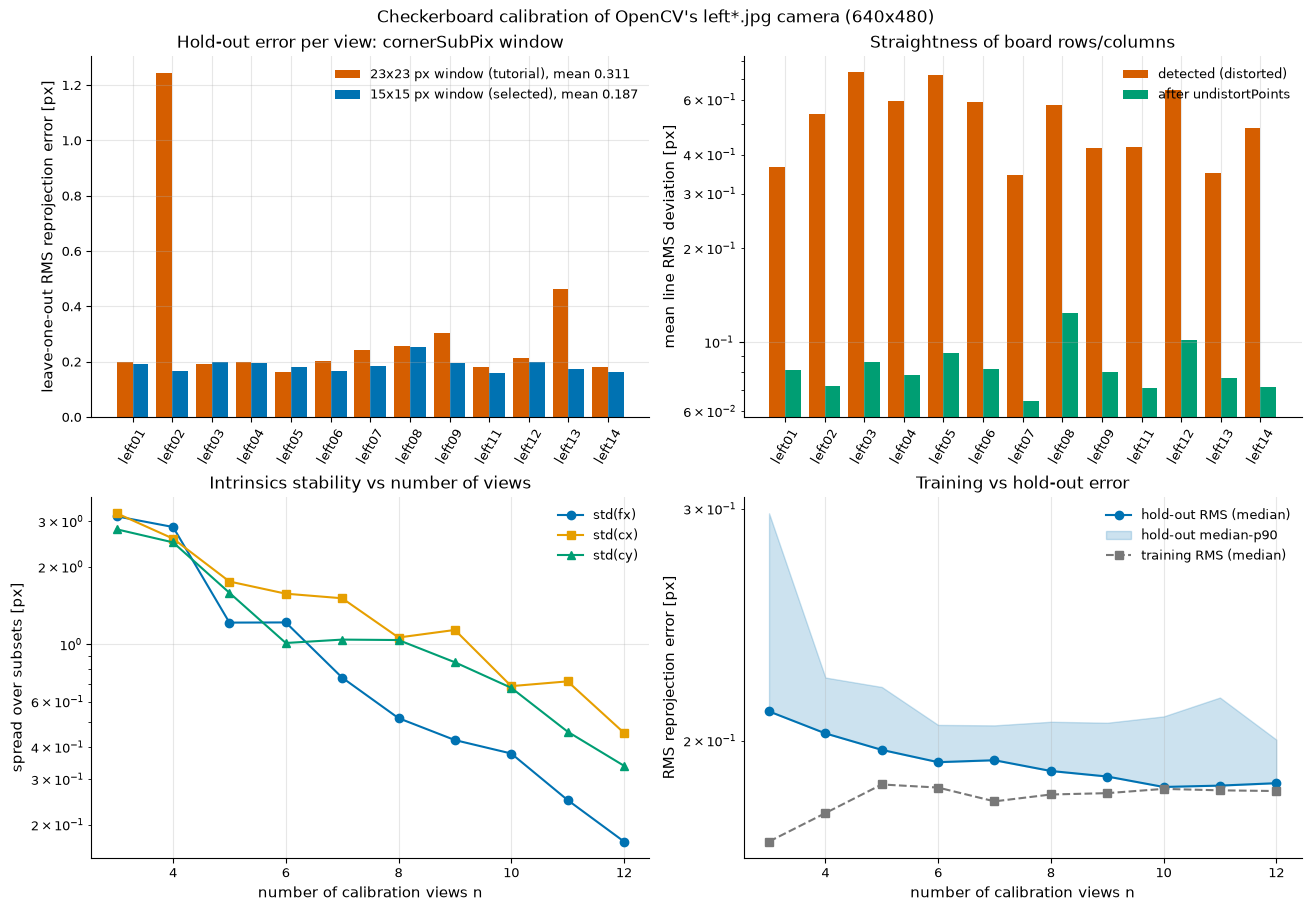

In [15]:
# --- Summary figure: per-view error, line straightness, parameter spread and hold-out error vs #views ---
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
ax = axes[0, 0]
xpos = np.arange(len(names))
ax.bar(xpos - 0.2, loo_tut, 0.4, color=viz.color(5, True), label=f"23x23 px window (tutorial), mean {loo_tut.mean():.3f}")
ax.bar(xpos + 0.2, loo_best, 0.4, color=viz.color(0, True),
       label=f"{2 * best_half + 1}x{2 * best_half + 1} px window (selected), mean {loo_best.mean():.3f}")
ax.set_xticks(xpos, names, rotation=60)
ax.set_ylabel("leave-one-out RMS reprojection error [px]")
ax.set_title("Hold-out error per view: cornerSubPix window")
ax.legend()

ax = axes[0, 1]
ax.bar(xpos - 0.2, df_straight["line_rms_distorted_px"], 0.4, color=viz.color(5, True), label="detected (distorted)")
ax.bar(xpos + 0.2, df_straight["line_rms_undistorted_px"], 0.4, color=viz.color(2, True), label="after undistortPoints")
ax.set_xticks(xpos, names, rotation=60)
ax.set_yscale("log")
ax.set_ylabel("mean line RMS deviation [px]")
ax.set_title("Straightness of board rows/columns")
ax.legend()

ax = axes[1, 0]
nv = agg.index.values
ax.plot(nv, agg["fx_std"], "o-", color=viz.color(0, True), label="std(fx)")
ax.plot(nv, agg["cx_std"], "s-", color=viz.color(1, True), label="std(cx)")
ax.plot(nv, agg["cy_std"], "^-", color=viz.color(2, True), label="std(cy)")
ax.set_yscale("log")
ax.set_xlabel("number of calibration views n")
ax.set_ylabel("spread over subsets [px]")
ax.set_title("Intrinsics stability vs number of views")
ax.legend()

ax = axes[1, 1]
ax.plot(nv, agg["holdout_rms_median"], "o-", color=viz.color(0, True), label="hold-out RMS (median)")
ax.fill_between(nv, agg["holdout_rms_median"], agg["holdout_rms_p90"], color=viz.color(0, True), alpha=0.2,
                label="hold-out median-p90")
ax.plot(nv, agg["train_rms_median"], "s--", color=viz.color(7, True), label="training RMS (median)")
ax.set_yscale("log")
ax.set_xlabel("number of calibration views n")
ax.set_ylabel("RMS reprojection error [px]")
ax.set_title("Training vs hold-out error")
ax.legend()
fig.suptitle("Checkerboard calibration of OpenCV's left*.jpg camera (640x480)")
viz.savefig(fig, PROJECT, "calibration_summary")
plt.show()

The summary table lists the final calibration and the headline diagnostics; everything (including $K$ and the distortion
vector) is also saved to `projects/01_classical_cv/results/nb03_calibration.json`.

In [16]:
# --- Summary table + JSON export ---
a3, a12 = agg.loc[3], agg.loc[12]
summary = [(f"{p} (final, 13 views)", v, s) for p, v, s in zip(param_names, cal["values"], cal["std"])]
summary += [
    ("cornerSubPix half-window (selected by LOO)", best_half, np.nan),
    ("training RMS, final [px]", rms, np.nan),
    ("training RMS, tutorial 11x11 half-window [px]", cal_tut["rms"], np.nan),
    ("mean leave-one-out RMS, final [px]", loo_best.mean(), np.nan),
    ("mean leave-one-out RMS, tutorial window [px]", loo_tut.mean(), np.nan),
    (f"leave-one-out RMS of {names[worst]}, tutorial window [px]", loo_tut[worst], np.nan),
    (f"leave-one-out RMS of {names[worst]}, final [px]", loo_best[worst], np.nan),
    ("fx from SB corners only (12 views) [px]", sb_cal["K"][0, 0], np.nan),
    ("classic detector success", len(corners), np.nan),
    ("SB detector success (EXHAUSTIVE|ACCURACY)", len(corners_sb), np.nan),
    ("mean line deviation, distorted [px]", df_straight["line_rms_distorted_px"].mean(), np.nan),
    ("mean line deviation, undistorted [px]", df_straight["line_rms_undistorted_px"].mean(), np.nan),
    ("std(fx) with 3 views [px]", a3["fx_std"], np.nan),
    ("std(fx) with 12 views [px]", a12["fx_std"], np.nan),
    ("median hold-out RMS, 3 views [px]", a3["holdout_rms_median"], np.nan),
    ("median hold-out RMS, 12 views [px]", a12["holdout_rms_median"], np.nan),
    ("cv2.undistort per frame [ms]", t_und["mean_ms"], np.nan),
    ("cv2.remap (precomputed maps) per frame [ms]", t_remap["mean_ms"], np.nan),
]
df_summary = pd.DataFrame(summary, columns=["quantity", "value", "std (1 sigma)"])
results["summary"] = df_summary.to_dict("records")
results["notebook_runtime_s"] = time.perf_counter() - T_START  # setup -> summary, CPU only
print(f"notebook runtime (setup to summary): {results['notebook_runtime_s']:.1f} s")
out = io.save_json(results, RESULTS_DIR / "nb03_calibration.json")
print("saved", out.relative_to(ROOT))
df_summary.style.format({"value": "{:.4g}", "std (1 sigma)": "{:.2g}"}, na_rep="").hide(axis="index")

notebook runtime (setup to summary): 6.5 s
saved projects/01_classical_cv/results/nb03_calibration.json


quantity,value,std (1 sigma)
"fx (final, 13 views)",533,0.41
"fy (final, 13 views)",533.1,0.43
"cx (final, 13 views)",342.3,0.43
"cy (final, 13 views)",233.9,0.48
"k1 (final, 13 views)",-0.2854,0.0051
"k2 (final, 13 views)",0.06385,0.039
"p1 (final, 13 views)",0.001107,0.0001
"p2 (final, 13 views)",-0.0001262,0.00013
"k3 (final, 13 views)",0.08172,0.083
cornerSubPix half-window (selected by LOO),7,


### Takeaways

- **A sub-pixel calibration from 13 hand-held photos.** With the selected refinement window the overall RMS is below 0.2 px,
  $f_x \approx f_y$ (square pixels) with formal 1-sigma uncertainties below half a pixel, and the strong barrel distortion
  ($k_1 < 0$) is clearly identified. $k_3$ is not significantly different from zero (its estimate is about one sigma).
- **A tutorial default can bias the result.** `cornerSubPix(winSize=(11, 11))` searches a 23x23 px window; with squares of
  only 32-46 px, the window around corners next to the board's border includes the border itself and drags those corners away.
  Two views became inconsistent with the rest (leave-one-out error 1.24 and 0.46 px vs about 0.2 px) and $f_x$ moved by about
  3 px, more than three of its own formal standard deviations. The formal $\sigma$ only describes random noise, never a
  systematic measurement bias.
- **Diagnose with hold-out error and independent measurements, then fix the cause.** Per-view residuals pointed at the bad
  corners, leave-one-out error ranked the views without the optimism of training error, and the window chosen by hold-out error
  (15x15 px) made every view consistent; its $f_x$ is within 0.7 px of the independent SB detector's estimate (the tutorial
  window was 3.7 px away).
- **Undistortion straightens the world.** Board rows and columns deviate from straight lines by about 0.5 px RMS on average
  (worst line about 1.9 px) in the raw images, and by about 0.08 px (worst line about 0.2 px) after `undistortPoints`. On a
  robot, precompute the maps once: `remap` is several times faster per frame than `undistort`, which rebuilds the maps on
  every call.
- **Use many, diverse views.** With 3 views $f_x$ varies by about 3 px between subsets and the training error underestimates the
  hold-out error (overfitting); with 12 views the spread drops below 0.2 px and both errors meet. Practical rule: 10-20 sharp
  views that cover the whole image, including the corners, with varied tilts.
- **Detector choice matters.** The classic detector found all 13 boards in a few milliseconds each; the SB detector with
  exhaustive search found 12 and takes far longer, but provides an excellent independent check.

## Exercises

Solutions: `projects/01_classical_cv/solutions/nb03_solutions.py` (run it from the repository root).

**Exercise 1: the stereo partner.** The data folder also contains `right*.jpg`, taken by the second camera of the same
stereo rig. Calibrate it the same way and compare $K$ and the distortion with the left camera. Are the differences larger
than the reported standard deviations?

In [17]:
# --- Exercise 1: calibrate the right camera ---
# TODO: load sorted(CALIB.glob("right*.jpg")), detect + refine the corners, run calibrateCameraExtended,
#       and print (K_right - K) / std for fx, fy, cx, cy.

**Exercise 2: how many distortion parameters?** Compare three distortion models with leave-one-out hold-out error over the
13 views: the full 5-parameter model, `CALIB_FIX_K3` (k1, k2, p1, p2) and `CALIB_FIX_K3 | CALIB_ZERO_TANGENT_DIST`
(k1, k2 only). Which one generalises best, and why can a model with more parameters be worse?

In [18]:
# --- Exercise 2: distortion-model selection with leave-one-out ---
# TODO: for each flag set, loop over the 13 views, calibrate on the other 12 with cv2.calibrateCamera(..., flags=flags),
#       evaluate holdout_rms(Kn, dn, [i]) on the left-out view and report the mean over views.

**Exercise 3: calibrate from SB corners.** Use the `corners_sb` dictionary (12 views) to calibrate, and compare $K$, the
RMS and the reported standard deviations with a calibration from the classic corners of the *same* 12 views.

In [19]:
# --- Exercise 3: SB corners vs classic sub-pixel corners ---
# TODO: build two lists over the views in corners_sb (SB corners and the matching classic corners),
#       calibrate both with calibrateCameraExtended and compare RMS, fx, cx and their std.